In [1]:
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
table = pd.read_csv("table-raw.csv")

In [3]:
def compression_ratio_pick_single(var: str, percentile: str) -> float:
    t = table[(table["level"] == "single") & (table["var"] == var) & (table["percentile"] == percentile)]
    p = t["pick"].iloc[0]
    return float(t["crbitround"].iloc[0]) if p == "relative" else float(t["crlinquant"].iloc[0])

In [4]:
def compression_ratio_pick_pressure(var: str, level: str, percentile: str) -> float:
    t = table[(table["level"] == level) & (table["var"] == var) & (table["percentile"] == percentile)]
    p = t["pick"].iloc[0]
    return float(t["crbitround"].iloc[0]) if p == "relative" else float(t["crlinquant"].iloc[0])

In [5]:
from matplotlib import pyplot as plt

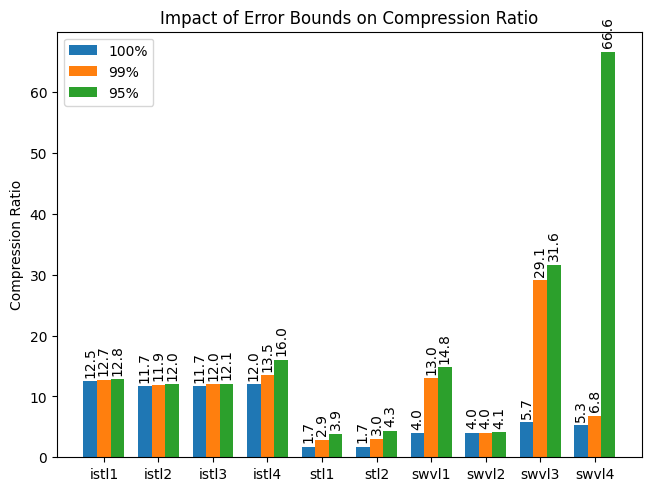

In [6]:
percentiles = ["100%", "99%", "95%"]
variables = sorted(table[table["level"] == "single"]["var"].unique()[:10])

x = np.arange(len(variables))
width = 0.25

fig, ax = plt.subplots(layout="constrained")

multiplier = 0
for p in percentiles:
    offset = width * multiplier
    rects = ax.bar(x + offset, [compression_ratio_pick_single(var, p) for var in variables], width, label=p)
    ax.bar_label(rects, fmt="%.1f", padding=3, rotation="vertical")
    multiplier += 1

ax.set_ylabel("Compression Ratio")
ax.set_title("Impact of Error Bounds on Compression Ratio")
ax.set_xticks(x + width, variables)
ax.legend()

plt.show()

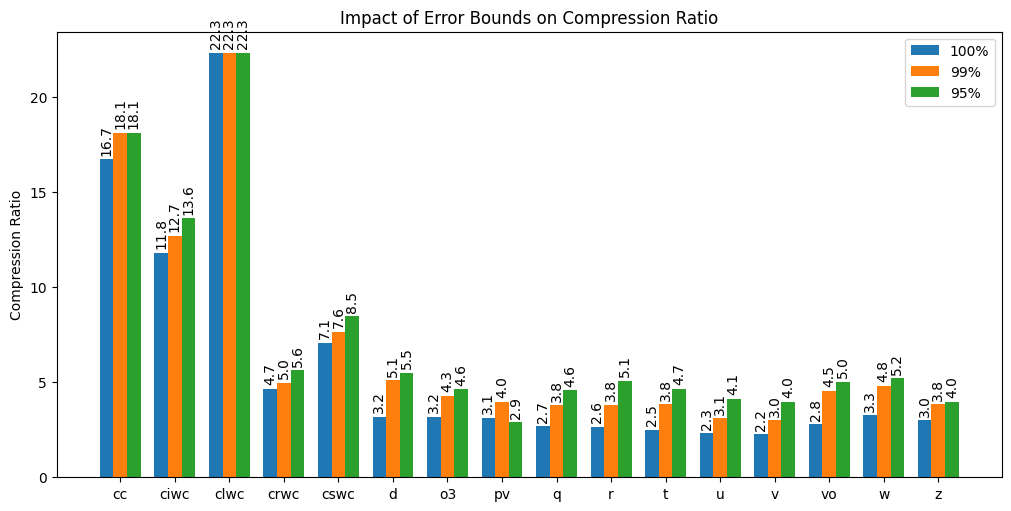

In [7]:
percentiles = ["100%", "99%", "95%"]
variables = sorted(table[table["level"] != "single"]["var"].unique())

x = np.arange(len(variables))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

multiplier = 0
for p in percentiles:
    offset = width * multiplier
    rects = ax.bar(x + offset, [compression_ratio_pick_pressure(var, "1000.0 hPa", p) for var in variables], width, label=p)
    ax.bar_label(rects, fmt="%.1f", padding=3, rotation="vertical")
    multiplier += 1

ax.set_ylabel("Compression Ratio")
ax.set_title("Impact of Error Bounds on Compression Ratio")
ax.set_xticks(x + width, variables)
ax.legend()

plt.show()